In [1]:
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
import numpy as np
import matplotlib
import seaborn as sns
import os
import tqdm

from matplotlib import pyplot as plt
from matplotlib.ticker import AutoMinorLocator
from corner import hist2d

matplotlib.rcParams.update(matplotlib.rcParamsDefault)

matplotlib.style.use("paper.style")
plt.rcParams['font.sans-serif'] = [ 'Helvetica', 'Nimbus Sans', 'FreeSans' ]
plt.rcParams['font.serif'] = [ 'Times', 'Nimbus Roman', 'FreeSerif' ]
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'stix'

sns.set_context("paper", font_scale=2.5, rc={"axes.labelsize":40})

In [3]:
CORNER_KWARGS = dict(
    show_titles=False,
    plot_contours=True,
    plot_datapoints=False,
    plot_density=False,
    levels=([0.9, 0.9, 0.9, 0.9]),
    quiet=True,
    bins=30,
    smooth=1.0,
    no_fill_contours=True,
)

color_joint = "C0"
color_hier = "C1"

# Update this path to point to files downloaded from the Zenodo data release
basedir = "/home/lorenzo.pompili/tgr/GWTC-4-data-release/tmp_data/NRSur_GaussianNoise_17"

In [4]:
Q0_boot_joint = np.zeros(1000)
Q0_boot_hier = np.zeros(1000)

for i in tqdm.tqdm(range(1000)):

    Q0_boot_hier[i] = np.loadtxt(f"{basedir}/Q0_hier_{i}.dat")
    Q0_boot_joint[i] = np.loadtxt(f"{basedir}/Q0_joint_{i}.dat")

 18%|█▊        | 181/1000 [00:00<00:00, 1807.20it/s]

100%|██████████| 1000/1000 [00:00<00:00, 1802.02it/s]


In [ ]:
idx_max_joint = np.argmax(Q0_boot_joint)

print(f"Max Q0 joint: {Q0_boot_joint[idx_max_joint]}")
print(idx_max_joint)

Max Q0 joint: 0.99975
493


  0%|          | 0/1000 [00:00<?, ?it/s]

100%|██████████| 1000/1000 [02:55<00:00,  5.70it/s]


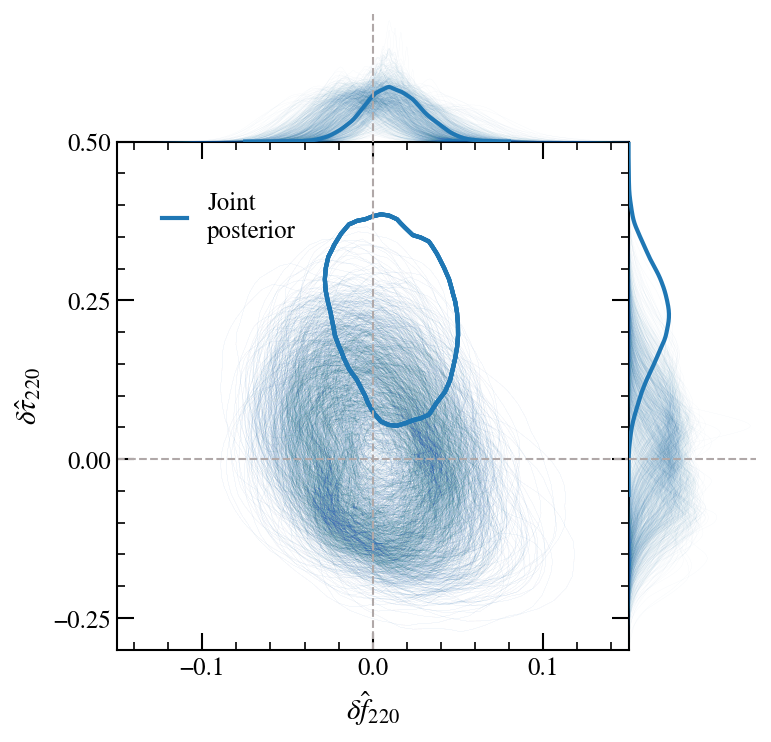

In [6]:
fig = plt.figure(figsize=(5.5, 5.5), dpi=300)
gs = fig.add_gridspec(ncols=2, nrows=2, width_ratios=[4, 1], height_ratios=[1, 4])

ax_joint = fig.add_subplot(gs[1, 0])
ax_df_220 = fig.add_subplot(gs[0, 0], sharex=ax_joint)
ax_dtau_220 = fig.add_subplot(gs[1, 1], sharey=ax_joint)
sns.despine(ax=ax_df_220)
sns.despine(ax=ax_dtau_220)
plt.subplots_adjust(hspace=0.0, wspace=0.0)

color = color_joint

for i in tqdm.tqdm(range(1000)):

    domega = np.loadtxt(f"{basedir}/domega220_joint_{i}.dat")
    dtau = np.loadtxt(f"{basedir}/dtau220_joint_{i}.dat")

    sns.kdeplot(x=domega, ax=ax_df_220, color=color, alpha=0.08, lw = 0.1)
    sns.kdeplot(y=dtau, ax=ax_dtau_220, color=color, alpha=0.08, lw = 0.1)
    hist2d(ax=ax_joint, x=domega, y=dtau, color=color, contour_kwargs={"alpha": 0.05, "linewidths": 0.1}, **CORNER_KWARGS)

# Plot the catalog giving max joint Q0
domega = np.loadtxt(f"{basedir}/domega220_joint_{idx_max_joint}.dat")
dtau = np.loadtxt(f"{basedir}/dtau220_joint_{idx_max_joint}.dat")

sns.kdeplot(x=domega, ax=ax_df_220, color=color, lw=2)
sns.kdeplot(y=dtau, ax=ax_dtau_220, color=color, lw=2)
hist2d(ax=ax_joint, x=domega, y=dtau, color=color, contour_kwargs={"alpha": 1, "linewidths": 2}, **CORNER_KWARGS)

df_220_min, df_220_max = -0.1, 0.1
dtau_220_min, dtau_220_max = -0.5, 0.5

tick_pos_x = np.linspace(df_220_min, df_220_max, num=3)
tick_pos_y = np.linspace(dtau_220_min, dtau_220_max, num=5)

ax_joint.set_xlabel(r"$\delta \hat{f}_{220}$", fontsize=14)
ax_joint.set_ylabel(r"$\delta \hat{\tau}_{220}$", fontsize=14)
ax_joint.set_xticks(tick_pos_x)
ax_joint.set_yticks(tick_pos_y)

ax_df_220.set_xlim(-0.15, 0.15)
ax_dtau_220.set_ylim(-0.3, 0.5)

linewidth = 1
ax_joint.xaxis.set_minor_locator(AutoMinorLocator())
ax_joint.yaxis.set_minor_locator(AutoMinorLocator())

tick_params = {
    "length": 4,
    "bottom": True,
    "left": True,
    "top": True,
    "right": True,
    "direction": "in",
    "zorder": 10,
}

major_tick_params = {**tick_params, "length": 8, "labelsize": 12}

for axis in ["x", "y"]:
    ax_joint.tick_params(axis=axis, which="minor", **tick_params)
    ax_joint.tick_params(axis=axis, which="major", **major_tick_params)

ax_joint.grid(visible=False)

ax_joint.axvline(0, ls="--", c="#b0a8a8", linewidth=linewidth)
ax_joint.axhline(0, ls="--", c="#b0a8a8", linewidth=linewidth)
ax_df_220.axvline(0, ls="--", c="#b0a8a8", linewidth=linewidth)
ax_dtau_220.axhline(0, ls="--", c="#b0a8a8", linewidth=linewidth)

ax_df_220.set_ylim(bottom=0.0)
ax_dtau_220.set_xlim(left=0.0)

ax_df_220.axis("off")
ax_dtau_220.axis("off")

from matplotlib.lines import Line2D

custom_lines = [
    Line2D([0], [0], color=color_joint, lw=2, linestyle="-", label="Joint\nposterior"),
]

ax_joint.legend(
    handles=custom_lines,
    loc="center left",
    bbox_to_anchor=(0.03, 0.85),
    frameon=False,
    prop={"size": 12},
    handlelength=1,
)

for ax in [ax_joint, ax_df_220, ax_dtau_220]:
    ax.set_rasterization_zorder(0)

os.makedirs("./plots", exist_ok=True)
plt.savefig("./plots/mock_catalog_joint.pdf", bbox_inches="tight")
plt.savefig("./plots/mock_catalog_joint.png", bbox_inches="tight")

fig.set_dpi(150)

plt.show()

  2%|▏         | 16/1000 [00:02<02:13,  7.36it/s]

100%|██████████| 1000/1000 [02:19<00:00,  7.16it/s]


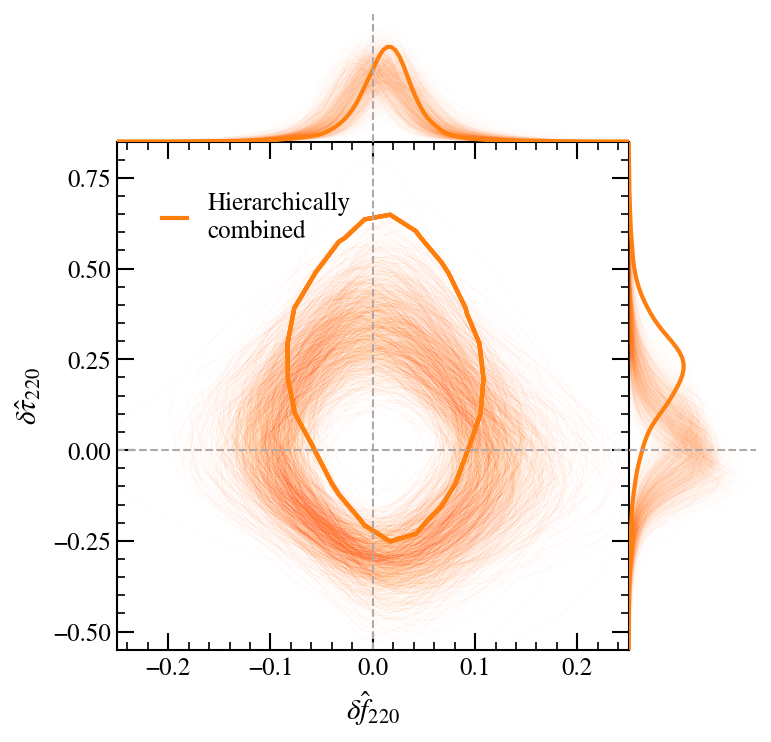

In [7]:
fig = plt.figure(figsize=(5.5, 5.5), dpi=300)
gs = fig.add_gridspec(ncols=2, nrows=2, width_ratios=[4, 1], height_ratios=[1, 4])

ax_joint = fig.add_subplot(gs[1, 0])
ax_df_220 = fig.add_subplot(gs[0, 0], sharex=ax_joint)
ax_dtau_220 = fig.add_subplot(gs[1, 1], sharey=ax_joint)
sns.despine(ax=ax_df_220)
sns.despine(ax=ax_dtau_220)
plt.subplots_adjust(hspace=0.0, wspace=0.0)

color = color_hier

for i in tqdm.tqdm(range(1000)):

    d = np.load(f"{basedir}/pop_hier_{i}.npz")
    domega = d["pop_domega_220"]
    dtau = d["pop_dtau_220"]

    sns.kdeplot(x=domega, ax=ax_df_220, color=color, alpha=0.06, lw = 0.1)
    sns.kdeplot(y=dtau, ax=ax_dtau_220, color=color, alpha=0.06, lw = 0.1)
    hist2d(ax=ax_joint, x=domega, y=dtau, color=color, contour_kwargs={"alpha": 0.04, "linewidths": 0.1}, **CORNER_KWARGS)

# Plot the catalog giving max joint Q0
d = np.load(f"{basedir}/pop_hier_{idx_max_joint}.npz")
domega = d["pop_domega_220"]
dtau = d["pop_dtau_220"]

sns.kdeplot(x=domega, ax=ax_df_220, color=color, lw=2)
sns.kdeplot(y=dtau, ax=ax_dtau_220, color=color, lw=2)
hist2d(ax=ax_joint, x=domega, y=dtau, color=color, contour_kwargs={"alpha": 1, "linewidths": 2}, **CORNER_KWARGS)

df_220_min, df_220_max = -0.2, 0.2
dtau_220_min, dtau_220_max = -0.5, 0.75

tick_pos_x = np.linspace(df_220_min, df_220_max, num=5)
tick_pos_y = np.linspace(dtau_220_min, dtau_220_max, num=6)

ax_joint.set_xlabel(r"$\delta \hat{f}_{220}$", fontsize=14)
ax_joint.set_ylabel(r"$\delta \hat{\tau}_{220}$", fontsize=14)
ax_joint.set_xticks(tick_pos_x)
ax_joint.set_yticks(tick_pos_y)

ax_df_220.set_xlim(-0.25, 0.25)
ax_dtau_220.set_ylim(-0.55, 0.85)

linewidth = 1
ax_joint.xaxis.set_minor_locator(AutoMinorLocator())
ax_joint.yaxis.set_minor_locator(AutoMinorLocator())

tick_params = {
    "length": 4,
    "bottom": True,
    "left": True,
    "top": True,
    "right": True,
    "direction": "in",
    "zorder": 10,
}

major_tick_params = {**tick_params, "length": 8, "labelsize": 12}

for axis in ["x", "y"]:
    ax_joint.tick_params(axis=axis, which="minor", **tick_params)
    ax_joint.tick_params(axis=axis, which="major", **major_tick_params)

ax_joint.grid(visible=False)

ax_joint.axvline(0, ls="--", c="#b0a8a8", linewidth=linewidth)
ax_joint.axhline(0, ls="--", c="#b0a8a8", linewidth=linewidth)
ax_df_220.axvline(0, ls="--", c="#b0a8a8", linewidth=linewidth)
ax_dtau_220.axhline(0, ls="--", c="#b0a8a8", linewidth=linewidth)

ax_df_220.set_ylim(bottom=0.0)
ax_dtau_220.set_xlim(left=0.0)

ax_df_220.axis("off")
ax_dtau_220.axis("off")

from matplotlib.lines import Line2D

custom_lines = [
    Line2D([0], [0], color=color_hier, lw=2, linestyle="-", label="Hierarchically\ncombined"),
]

ax_joint.legend(
    handles=custom_lines,
    loc="center left",
    bbox_to_anchor=(0.03, 0.85),
    frameon=False,
    prop={"size": 12},
    handlelength=1,
)

plt.savefig("./plots/mock_catalog_hier.pdf", bbox_inches="tight")
plt.savefig("./plots/mock_catalog_hier.png", bbox_inches="tight")

fig.set_dpi(150)

plt.show()